# Imports

In [5]:
import os
import kagglehub
import pathlib
import torch
import torch.nn as nn
from typing import List
import torchvision
from torchvision import tv_tensors
from torchvision.transforms import v2 as tv_transform
from torchvision.transforms.functional import to_pil_image
import numpy as np
import matplotlib.pyplot as plt

import random
random.seed(67)
torch.manual_seed(67)
np.random.seed(67)

torch.set_default_device("cuda")
torch.cuda.is_available()

False

# Dataset Handling

In [4]:
preload_transform = tv_transform.Compose([ tv_transform.ToTensor(), tv_transform.Grayscale(), tv_transform.Resize([256,256]), tv_transform.ToDtype(torch.float32, scale=True) ])

DATASET = torchvision.datasets.ImageFolder( kagglehub.dataset_download("samithsachidanandan/human-face-emotions")+'/Data', preload_transform )
generator = torch.Generator(device='cuda')
train_split, val_split, test_split = torch.utils.data.random_split(DATASET, [0.7, 0.15, 0.15], generator=generator)
train_loader = torch.utils.data.DataLoader(train_split, batch_size=32, shuffle=True, generator=generator, num_workers=4, pin_memory=True)

RuntimeError: Cannot get CUDA generator without ATen_cuda library. PyTorch splits its backend into two shared libraries: a CPU library and a CUDA library; this error has occurred because you are trying to use some CUDA functionality, but the CUDA library has not been loaded by the dynamic linker for some reason.  The CUDA library MUST be loaded, EVEN IF you don't directly use any symbols from the CUDA library! One common culprit is a lack of -INCLUDE:?warp_size@cuda@at@@YAHXZ in your link arguments; many dynamic linkers will delete dynamic library dependencies if you don't depend on any of their symbols.  You can check if this has occurred by using link on your binary to see if there is a dependency on *_cuda.dll library.

In [ ]:
DATASET.classes

['Angry', 'Fear', 'Happy', 'Sad', 'Suprise']

In [ ]:
DATASET.__len__()

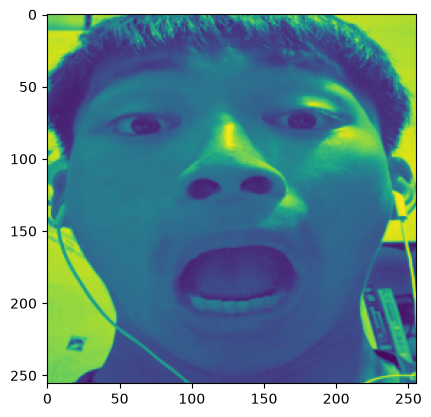

In [ ]:
plt.imshow( to_pil_image( DATASET[-31][0] ) )

# Model

In [ ]:
class CNN(nn.Module):
    def __init__(self, CNNShape: List[int] = [16, 32, 64, 256, 512], MLPShape: List[int] = [16, 16, 16], outSize:int = 5):
        super().__init__()

        self.CNNlayers = nn.Sequential()
        for size in CNNShape:
            self.CNNlayers.append( nn.LazyConv2d(size, kernel_size=3, padding=1) )
            self.CNNlayers.append( nn.BatchNorm2d(size) )
            self.CNNlayers.append( nn.ReLU() )
            self.CNNlayers.append( nn.AvgPool2d(2, 2) )
        
        self.CNNlayers.append(nn.AdaptiveAvgPool2d((1, 1)))


        self.MLPlayers = nn.Sequential( nn.Flatten() )
        for size in MLPShape:
            self.MLPlayers.append( nn.LazyLinear(size) )
            self.MLPlayers.append( nn.ReLU() )
        
        self.MLPlayers.append( nn.LazyLinear(outSize) )
        
    def forward(self, x):
        return self.MLPlayers( self.CNNlayers(x) )

model = CNN(outSize=len(DATASET.classes))

In [ ]:
model( DATASET[0][0].unsqueeze(0) )

tensor([[-0.1694, -0.0195,  0.0632, -0.0874,  0.1683]],
       grad_fn=<AddmmBackward0>)

# Model Training

In [ ]:
EPOCHS = 100
CRITERIA = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)

for i in range(EPOCHS+1):
    model.train()

    loss_avg = 0
    for imgs, y in train_loader:
        optimizer.zero_grad()
        y_hat = model(imgs)

        loss = CRITERIA(y_hat, y)
        loss_avg += loss
        print(f"Loss: {loss}")
        loss.backward()
        optimizer.step()

    model.eval()
    print(f"Average Loss: {loss_avg}")

Loss: 1.6212146282196045


KeyboardInterrupt: 